# Advanced Natural Language Processing (968G5): Practical Assignment (Max 5000 words) - Propaganda Detection

## 1. Setup

### 1.1. Load Libraries

In [3]:
from collections import Counter
from datasets import Dataset
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.naive_bayes import MultinomialNB
from torch.optim import AdamW
from torch.utils.data import DataLoader
from tqdm import tqdm
from transformers import AutoModelForSequenceClassification, AutoModelForTokenClassification, AutoTokenizer, DataCollatorWithPadding, DataCollatorForTokenClassification
import csv
import matplotlib.pyplot as plt
import nltk
import numpy as np
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8" # for reproducibility
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
import pandas as pd
import pickle
import random
import re
import scipy as sp
import seaborn as sns
import torch
import torch.nn as nn

### 1.2. Initialise Settings

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed = 123

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)

set_seed(seed)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(seed)

### 1.3. Create Folders

In [5]:
folders = ["data", "figures", "metrics", "tables"]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

### 1.4. Read in Data

In [6]:
train_df = pd.read_csv(
    "data/propaganda_train.tsv",
    sep="\t",
    engine="python",
    quoting=csv.QUOTE_NONE,
    on_bad_lines="warn"
)

test_df = pd.read_csv(
    "data/propaganda_val.tsv",
    sep="\t",
    engine="python",
    quoting=csv.QUOTE_NONE,
    on_bad_lines="warn"
)

# Note: Some of the rows in the .tsv files 
# had malformed quote marks which prevented 
# pandas from reading in rows correctly. 
# quoting=csv.QUOTE_NONE just ensures read_csv
# escapes quote marks correctly.

### 1.5. Data Preprocessing

#### 1.5.1. Create Cleaned Text

In [7]:
train_df["cleaned_text"] = (
    train_df["tagged_in_context"]
    .str.replace(r"<BOS>|<EOS>", "", regex=True)
    .str.replace(r" ([^\w\s])", r"\1", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

test_df["cleaned_text"] = (
    test_df["tagged_in_context"]
    .str.replace(r"<BOS>|<EOS>", "", regex=True)
    .str.replace(r" ([^\w\s])", r"\1", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [8]:
train_df["cleaned_text_len"] = train_df["cleaned_text"].apply(lambda x: len(x.split()))
test_df["cleaned_text_len"] = test_df["cleaned_text"].apply(lambda x: len(x.split()))

## 2. EDA

### 2.1. Class Distribution

In [9]:
multiclass_proportion_train_df = train_df["label"].value_counts(normalize=True).reset_index()
multiclass_proportion_test_df = test_df["label"].value_counts(normalize=True).reset_index()

multiclass_proportion_train_df["split"] = "train"
multiclass_proportion_test_df["split"] = "test"

combined_multiclass_proportion_df = pd.concat([
    multiclass_proportion_train_df, 
    multiclass_proportion_test_df
])

In [10]:
multiclass_order = sorted(combined_multiclass_proportion_df["label"].unique())
palette = {k: v for k, v in zip(multiclass_order, sns.color_palette()[:len(multiclass_order)])}

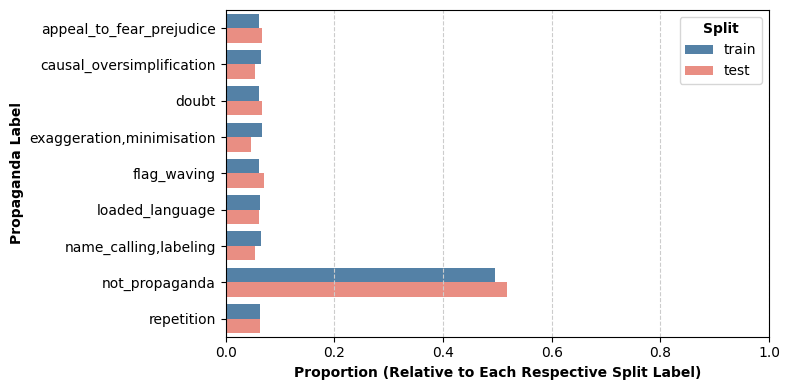

In [11]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=combined_multiclass_proportion_df,
    x="proportion",
    y="label",
    hue="split",
    order=multiclass_order,
    palette={"train": "steelblue", "test": "salmon"}
)

plt.xlabel("Proportion (Relative to Each Respective Split Label)", fontsize=10, fontweight="bold")
plt.ylabel("Propaganda Label", fontsize=10, fontweight="bold")

plt.xlim(0, 1)

plt.grid(axis="x", color="0.8", linestyle="--")

plt.legend(
    title="Split",
    title_fontproperties={
        "size": 10, 
        "weight": "bold"
    }
)

plt.tight_layout()
plt.savefig(
    "figures/class_distribution_comparison_plot.png",
    dpi=600
)
plt.show()

### 2.2 Snippet and Sentential Context

In [12]:
def extract_span_and_context(text):
    span_match = re.search(r"<BOS>(.*?)<EOS>", text)
    span = span_match.group(1).strip() if span_match else ""
    context = re.sub(r"<BOS>.*?<EOS>", "", text)
    context = re.sub(r"\s+", " ", context).strip()
    if not re.search(r"[A-Za-z0-9]", context):
        context = ""
    return span, context

train_df[["snippet", "context"]] = train_df["tagged_in_context"].apply(
    lambda x: pd.Series(extract_span_and_context(x))
)

test_df[["snippet", "context"]] = test_df["tagged_in_context"].apply(
    lambda x: pd.Series(extract_span_and_context(x))
)

In [13]:
full_dataset_df = pd.concat([train_df, test_df])

propaganda_only_df = full_dataset_df[full_dataset_df["label"] != "not_propaganda"]

In [14]:
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

labels = propaganda_only_df["label"].unique()

def get_top_ngrams(text, n=10):
    words = re.findall(r'\b\w+\b', text.lower())
    
    unigrams = [w for w in words if w not in stop_words]

    bigrams = [
        f"{w1} {w2}"
        for w1, w2 in zip(words, words[1:])
        if not (w1 in stop_words and w2 in stop_words)
    ]

    all_terms = unigrams + bigrams

    return [term for term, _ in Counter(all_terms).most_common(n)]

most_common_words_data = {
    "snippet": {},
    "context": {}
}

for label in labels:
    subset = propaganda_only_df[propaganda_only_df["label"] == label]

    snippet_text = " ".join(subset["snippet"].dropna().astype(str))
    context_text = " ".join(subset["context"].dropna().astype(str))

    most_common_words_data["snippet"][label] = ", ".join(
        get_top_ngrams(snippet_text)
    )

    most_common_words_data["context"][label] = ", ".join(
        get_top_ngrams(context_text)
    )

most_common_words_df = pd.DataFrame(most_common_words_data).reset_index(names="label").sort_values("label")
most_common_words_df.columns = [c.title() for c in most_common_words_df.columns]

most_common_words_df.to_csv("tables/most_common_words_df.csv", index=False)

most_common_words_df

,Label,Snippet,Context
4,appeal_to_fear_prejudice,"church, one, would, the church, people, u, u s...","said, many, letter, us, trump, plague, could, ..."
6,causal_oversimplification,"one, god, cia, church, the cia, the church, tr...","said, one, would, security, like, words, natio..."
2,doubt,"guardian, the guardian, people, even, evidence...","said, church, question, also, cannot, kavanaug..."
7,"exaggeration,minimisation","world, one, history, ever, thing, the world, c...","one, trump, said, president, people, one of, c..."
0,flag_waving,"american, people, america, american people, th...","trump, said, continue, president, public, put,..."
1,loaded_language,"church, people, life, smear, whoa, scandal, po...","trump, church, said, would, also, new, many, t..."
3,"name_calling,labeling","trump, leftist, left, america, disgrace, anti,...","trump, one, would, church, news, assange, cath..."
5,repetition,"aliens, people, autonomy, trump, illegal, ille...","one, said, parents, trump, many, obama, school..."


## 3. Modelling

### 3.1. Task 1: Propaganda Snippet Multimodal Classification

In [15]:
propaganda_only_train_df = train_df[train_df["label"] != "not_propaganda"][["label", "tagged_in_context", "snippet", "context"]].reset_index(drop=True)
propaganda_only_test_df = test_df[test_df["label"] != "not_propaganda"][["label", "tagged_in_context", "snippet", "context"]].reset_index(drop=True)

#### 3.1.1. Method 1: Multimodal Naive Bayes

In [16]:
snippet_vectoriser = CountVectorizer(ngram_range=(1, 2), min_df=2, token_pattern=r"\w+|[!?]")
context_vectoriser = CountVectorizer(ngram_range=(1, 2), min_df=2, token_pattern=r"\w+|[!?]")

X_train_snippet_vectors = snippet_vectoriser.fit_transform(propaganda_only_train_df["snippet"])
X_train_context_vectors = context_vectoriser.fit_transform(propaganda_only_train_df["context"])

X_test_snippet_vectors = snippet_vectoriser.transform(propaganda_only_test_df["snippet"])
X_test_context_vectors = context_vectoriser.transform(propaganda_only_test_df["context"])

X_train_concatenated_vectors = sp.sparse.hstack([X_train_snippet_vectors, X_train_context_vectors])
X_test_concatenated_vectors = sp.sparse.hstack([X_test_snippet_vectors, X_test_context_vectors])

In [17]:
classifier=MultinomialNB()
classifier.fit(X_train_concatenated_vectors, propaganda_only_train_df["label"])
y_pred = classifier.predict(X_test_concatenated_vectors)
y_true = propaganda_only_test_df["label"]

In [18]:
with open("metrics/multimodalNB_accuracy.pkl", "wb") as f:
    pickle.dump(accuracy_score(y_true, y_pred), f)

print(f"{accuracy_score(y_true, y_pred):.3f}")

0.411


In [19]:
multinomialNB_classification_report = classification_report(
    y_true, 
    y_pred, 
    output_dict=True
)

In [20]:
multinomialNB_classification_report_df = (
    pd.DataFrame(multinomialNB_classification_report)
    .transpose()
    .drop(columns="support")
    .reset_index(names="label")
)

multinomialNB_classification_report_df["label"] = multinomialNB_classification_report_df["label"].apply(
    lambda x: x.replace("_", " ").title()
)

multinomialNB_classification_report_df.columns = [c.title() for c in multinomialNB_classification_report_df.columns]
multinomialNB_classification_report_df

,Label,Precision,Recall,F1-Score
0,Appeal To Fear Prejudice,0.312500,0.232558,0.266667
1,Causal Oversimplification,0.368421,0.600000,0.456522
2,Doubt,0.489362,0.534884,0.511111
3,"Exaggeration,Minimisation",0.363636,0.400000,0.380952
4,Flag Waving,0.529412,0.400000,0.455696
5,Loaded Language,0.458333,0.282051,0.349206
6,"Name Calling,Labeling",0.363636,0.588235,0.449438
7,Repetition,0.444444,0.300000,0.358209
8,Accuracy,0.411003,0.411003,0.411003
9,Macro Avg,0.416218,0.417216,0.403475


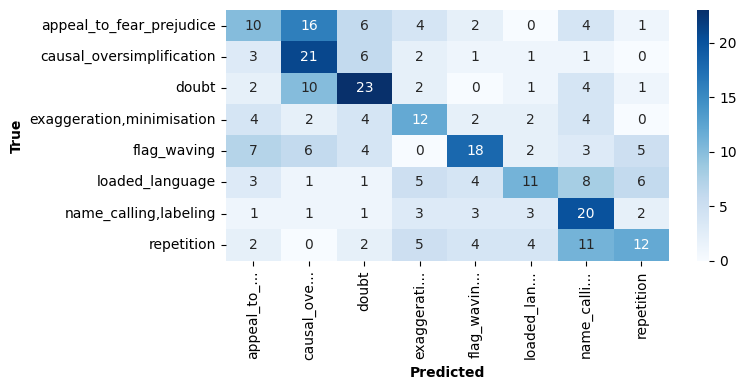

In [21]:
conf_matrix = confusion_matrix(
    y_true, 
    y_pred, 
    labels=classifier.classes_
)

truncated_class_labels = [str(c)[:10] + "..." if len(c) > 10 else str(c) for c in classifier.classes_]

plt.figure(figsize=(8,4))

sns.heatmap(
    conf_matrix, 
    annot=True, 
    xticklabels=truncated_class_labels, 
    yticklabels=classifier.classes_, 
    cmap="Blues"
)

plt.xlabel("Predicted", fontsize=10, fontweight="bold")
plt.ylabel("True", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("figures/mutlinomialNB_confusion_matrix_plot.png", dpi=600)
plt.show()

In [22]:
snippet_features = snippet_vectoriser.get_feature_names_out()
context_features = context_vectoriser.get_feature_names_out()

feature_names = np.concatenate([snippet_features, context_features])

def most_discriminative_features_per_class(classifier, feature_names, class_labels, top_n=10):
    
    log_probs = classifier.feature_log_prob_
    n_classes = log_probs.shape[0]
    
    rows = []
    
    for i in range(n_classes):

        others = np.mean(
            np.delete(log_probs, i, axis=0),
            axis=0
        )
        
        scores = log_probs[i] - others
        
        top_idx = np.argsort(scores)[::-1][:top_n]
        
        top_words = [feature_names[j] for j in top_idx]
        
        rows.append({
            "Label": class_labels[i],
            "Most Discriminative Features": ", ".join(top_words)
        })
    
    return pd.DataFrame(rows)

most_discriminative_features_per_class_df = most_discriminative_features_per_class(
    classifier=classifier,
    feature_names=feature_names,
    class_labels=classifier.classes_,
    top_n=10
)

most_discriminative_features_per_class_df.to_csv("tables/most_discriminative_features_per_class_df.csv", index=False)

most_discriminative_features_per_class_df

,Label,Most Discriminative Features
0,appeal_to_fear_prejudice,"if, we, iran, face, will, letter, the easiest,..."
1,causal_oversimplification,"because, she, clearly, it is, the cia, cia, if..."
2,doubt,"guardian, the guardian, why, ?, but, evidence,..."
3,"exaggeration,minimisation","the most, most, world s, thing, history, weapo..."
4,flag_waving,"american people, the american, american, our, ..."
5,loaded_language,"evidence, that no, it was, wills, region, hous..."
6,"name_calling,labeling","jews, account, nothing, account was, news and,..."
7,repetition,"parents, aliens, school, curriculum, autonomy,..."


#### 3.1.2. Method 2: BERT

##### 3.1.2.1. BERT Hyperparameters

In [23]:
batch_size = 8
learning_rate = 1e-5
num_epochs = 5
pretrained_bert_model = "distilbert-base-uncased"
validation_set_size = 0.2
weight_decay = 0.1

In [24]:
train_dataset = Dataset.from_pandas(propaganda_only_train_df[["label", "tagged_in_context"]])
test_dataset = Dataset.from_pandas(propaganda_only_test_df[["label", "tagged_in_context"]])

In [25]:
set_seed(seed)

unique_labels = sorted(propaganda_only_train_df["label"].unique())
label2id = {label: i for i, label in enumerate(unique_labels)}
id2label = {i: label for i, label in enumerate(unique_labels)}

tokeniser = AutoTokenizer.from_pretrained(pretrained_bert_model)

special_tokens = {"additional_special_tokens": ["<BOS>", "<EOS>"]}
tokeniser.add_special_tokens(special_tokens)

model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_bert_model, 
    num_labels=len(unique_labels), 
    id2label=id2label, 
    label2id=label2id
)

model.resize_token_embeddings(len(tokeniser))

model = model.to(device)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 5555.59it/s]
DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nl

In [26]:
def tokenize(example):
    return tokeniser(
        example["tagged_in_context"],
        truncation=True,
        max_length=512
    )

def add_labels(example):
    example["labels"] = label2id[example["label"]]
    return example

train_dataset = train_dataset.map(tokenize, batched=True)
train_dataset = train_dataset.map(add_labels)

test_dataset = test_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(add_labels)

train_dataset = train_dataset.remove_columns(["label"])
test_dataset = test_dataset.remove_columns(["label"])

train_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

test_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

data_collator = DataCollatorWithPadding(tokenizer=tokeniser)

Map: 100%|██████████| 309/309 [00:00<00:00, 15451.30 examples/s]


In [27]:
train_validation_dataset = train_dataset.train_test_split(
    test_size=validation_set_size, 
    seed=seed
)

In [28]:
train_sampler = torch.utils.data.RandomSampler(
    train_validation_dataset["train"]
)

val_sampler = torch.utils.data.SequentialSampler(
    train_validation_dataset["test"]
)

test_sampler = torch.utils.data.SequentialSampler(
    test_dataset
)

train_loader = DataLoader(
    train_validation_dataset["train"],
    batch_size=batch_size,
    collate_fn=data_collator,
    sampler=train_sampler,
    worker_init_fn=seed_worker,
    generator=g, 
)

val_loader = DataLoader(
    train_validation_dataset["test"],
    batch_size=batch_size,
    collate_fn=data_collator,
    sampler=val_sampler,
    worker_init_fn=seed_worker,
    generator=g, 
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=data_collator,
    sampler=test_sampler,
    worker_init_fn=seed_worker,
    generator=g, 
)

In [29]:
set_seed(seed)

losses_dict = {
    "epoch": [],
    "train": [],
    "validation": []
}

optimiser = AdamW(
    params=model.parameters(), 
    lr=learning_rate,
    weight_decay=weight_decay
)

for epoch in range(num_epochs):
    model.train()
    total_loss = 0

    for batch in tqdm(train_loader, desc=f"Processing Batches from Epoch {epoch+1}"):
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = model(**batch)
        loss = outputs.loss

        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader)

    model.eval()
    val_preds = []
    val_true = []
    val_loss = 0

    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}

            outputs = model(**batch)
            val_loss += outputs.loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_true.extend(batch["labels"].cpu().numpy())

    avg_val_loss = val_loss / len(val_loader)
    val_acc = accuracy_score(val_true, val_preds)

    losses_dict["epoch"].append(epoch+1)
    losses_dict["train"].append(avg_train_loss)
    losses_dict["validation"].append(avg_val_loss)

    print(f"--- Epoch {epoch+1} Results ---")
    print(f"Train Loss: {avg_train_loss:.4f}")
    print(f"Val Loss: {avg_val_loss:.4f}")
    print(f"Val Accuracy: {val_acc:.4f}\n")

Processing Batches from Epoch 1: 100%|██████████| 129/129 [00:09<00:00, 13.14it/s]


--- Epoch 1 Results ---
Train Loss: 2.0634
Val Loss: 2.0289
Val Accuracy: 0.2973



Processing Batches from Epoch 2: 100%|██████████| 129/129 [00:09<00:00, 13.30it/s]


--- Epoch 2 Results ---
Train Loss: 1.9081
Val Loss: 1.8334
Val Accuracy: 0.3514



Processing Batches from Epoch 3: 100%|██████████| 129/129 [00:09<00:00, 13.60it/s]


--- Epoch 3 Results ---
Train Loss: 1.5860
Val Loss: 1.6198
Val Accuracy: 0.4093



Processing Batches from Epoch 4: 100%|██████████| 129/129 [00:09<00:00, 13.65it/s]


--- Epoch 4 Results ---
Train Loss: 1.2086
Val Loss: 1.4815
Val Accuracy: 0.4595



Processing Batches from Epoch 5: 100%|██████████| 129/129 [00:09<00:00, 13.42it/s]


--- Epoch 5 Results ---
Train Loss: 0.8528
Val Loss: 1.4360
Val Accuracy: 0.4865



In [30]:
model.eval()

test_preds = []
test_true = []

with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = model(**batch)
        logits = outputs.logits

        preds = torch.argmax(logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_true.extend(batch["labels"].cpu().numpy())

bert_accuracy = accuracy_score(test_true, test_preds)

with open("metrics/bert_accuracy.pkl", "wb") as f:
    pickle.dump(bert_accuracy, f)

print(f"Test Accuracy: {bert_accuracy:.4f}")

Test Accuracy: 0.5146


In [31]:
BERT_classification_report = classification_report(
    test_true, 
    test_preds, 
    output_dict=True
)

In [32]:
BERT_classification_report_label_mapping = {str(k): v for k, v in id2label.items()}

In [33]:
BERT_classification_report_df = (
    pd.DataFrame(BERT_classification_report)
    .drop(columns="accuracy")
    .transpose()
    .drop(columns="support")
    .reset_index(names="label")
)

BERT_classification_report_df["label"] = (
    BERT_classification_report_df["label"]
    .map(BERT_classification_report_label_mapping)
    .fillna(BERT_classification_report_df["label"])
)

BERT_classification_report_df["label"] = BERT_classification_report_df["label"].apply(
    lambda x: x.replace("_", " ").title()
)

BERT_classification_report_df.columns = [c.title() for c in BERT_classification_report_df.columns]

BERT_classification_report_df

,Label,Precision,Recall,F1-Score
0,Appeal To Fear Prejudice,0.549020,0.651163,0.595745
1,Causal Oversimplification,0.483871,0.428571,0.454545
2,Doubt,0.561404,0.744186,0.640000
3,"Exaggeration,Minimisation",0.433333,0.433333,0.433333
4,Flag Waving,0.684211,0.577778,0.626506
5,Loaded Language,0.369565,0.435897,0.400000
6,"Name Calling,Labeling",0.583333,0.411765,0.482759
7,Repetition,0.437500,0.350000,0.388889
8,Macro Avg,0.512780,0.504087,0.502722
9,Weighted Avg,0.518510,0.514563,0.510706


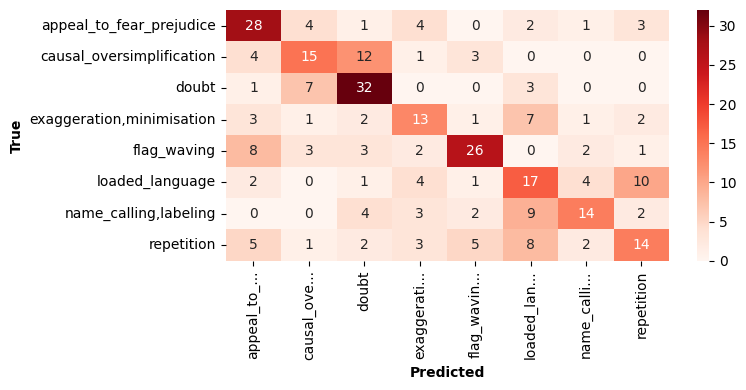

In [34]:
conf_matrix = confusion_matrix(
    test_true, 
    test_preds
)

truncated_class_labels = [str(c)[:10] + "..." if len(c) > 10 else str(c) for c in unique_labels]

plt.figure(figsize=(8,4))

sns.heatmap(
    conf_matrix, 
    annot=True, 
    xticklabels=truncated_class_labels, 
    yticklabels=unique_labels, 
    cmap="Reds"
)

plt.xlabel("Predicted", fontsize=10, fontweight="bold")
plt.ylabel("True", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("figures/BERT_confusion_matrix_plot.png", dpi=600)
plt.show()

### 3.2 Task 2: Propaganda Span Identification + Multimodal Classification

#### 3.2.1 Method 1: Brute-force Span Enumeration with Binary + Multinomial Naive Bayes Classifier

In [35]:
binary_train_df = train_df.copy()
binary_train_df["binary_label"] = binary_train_df["label"].apply(
    lambda x: "not_propaganda" if x == "not_propaganda" else "propaganda"
)

binary_vectoriser = CountVectorizer(ngram_range=(1, 2), min_df=2, token_pattern=r"\w+|[!?]")
X_train_binary = binary_vectoriser.fit_transform(binary_train_df["cleaned_text"])

binary_classifier = MultinomialNB()
binary_classifier.fit(X_train_binary, binary_train_df["binary_label"])

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [36]:
def get_candidate_spans(tokens):
    words = tokens.split()
    n = len(words)

    prefix = [""] * (n + 1)
    for i in range(n):
        prefix[i+1] = prefix[i] + (" " if i > 0 else "") + words[i]

    suffix = [""] * (n + 1)
    for i in range(n - 1, -1, -1):
        suffix[i] = words[i] + (" " if i < n - 1 else "") + suffix[i+1]

    for i in range(n):
        for j in range(i + 1, n + 1):
            span = prefix[j][len(prefix[i]):].strip()

            left_context = prefix[i]
            right_context = suffix[j]

            if left_context and right_context:
                context = left_context + " " + right_context
            else:
                context = left_context or right_context

            yield span, context

def predict_span_and_label(sentence):

    binary_vec = binary_vectoriser.transform([sentence])
    binary_pred = binary_classifier.predict(binary_vec)[0]

    if binary_pred == "not_propaganda":
        return "", "not_propaganda"

    else:
        candidates = get_candidate_spans(sentence)

        best_span = ""
        best_label = ""
        best_score = 0

        for span, context in candidates:

            snippet_vec = snippet_vectoriser.transform([span])
            context_vec = context_vectoriser.transform([context])

            combined_vec = sp.sparse.hstack([snippet_vec, context_vec])

            probs = classifier.predict_proba(combined_vec)[0]
            pred_label = classifier.classes_[probs.argmax()]
            score = probs.max()

            if score > best_score:
                best_span = span
                best_label = pred_label
                best_score = score

    if best_span:
        return best_span, best_label

task_2_results_df = test_df.copy()

task_2_results_df[["identified_snippet", "predicted_label"]] = task_2_results_df["cleaned_text"].apply( 
    lambda x: pd.Series(predict_span_and_label(x)) 
)

In [37]:
def token_f1(pred, gold): 
    pred_tokens = pred.lower().split() 
    gold_tokens = gold.lower().split() 
    common = set(pred_tokens) & set(gold_tokens) 
    if not common: 
        return 0 
    precision = len(common) / len(pred_tokens) 
    recall = len(common) / len(gold_tokens) 
    
    return 2 * precision * recall / (precision + recall) 
    
mask = task_2_results_df["label"] == task_2_results_df["predicted_label"]

task_2_results_df.loc[mask, "span_f1"] = task_2_results_df.loc[mask].apply(
    lambda row: token_f1(row["identified_snippet"], row["snippet"]),
    axis=1
)

print(f"""
Token-level F1: {task_2_results_df["span_f1"].mean():.4f}
""")


Token-level F1: 0.1249



#### 3.2.2 BIO Tagging with BERT

In [57]:
batch_size = 8
learning_rate = 1e-5
num_epochs = 5
pretrained_bert_model = "distilbert-base-uncased" 
validation_set_size = 0.2 
weight_decay = 0.1

In [58]:
def bio_tag(text, label): 

    text = re.sub(r"<EOS>\S+", "<EOS>", text) 
    tokens = text.split() 
    tags = [] 
    inside = False 
    first_inside = False

    for token in tokens: 

        if token == "<BOS>": 
            inside = True 
            first_inside = True 
            continue 

        elif token == "<EOS>":
            inside = False 
            continue 
        
        if inside: 
            if first_inside: 
                tags.append(f"B-{label}") 
                first_inside = False 
            else: 
                tags.append(f"I-{label}") 
        else: 
            tags.append("O") 
    
    cleaned_tokens = [t for t in tokens if t not in ("<BOS>", "<EOS>")] 
    
    return list(zip(cleaned_tokens, tags)) 
    
train_df["bio_tagged_text"] = train_df.apply( 
    lambda row: bio_tag(row["tagged_in_context"], row["label"]), axis=1 
) 

test_df["bio_tagged_text"] = test_df.apply( 
    lambda row: bio_tag(row["tagged_in_context"], row["label"]), axis=1 
)

In [59]:
all_tags = set() 

for bio_list in train_df["bio_tagged_text"]: 
    for _, tag in bio_list: 
        all_tags.add(tag) 

unique_tags = sorted(all_tags) 
tag2id = {tag: i for i, tag in enumerate(unique_tags)} 
id2tag = {i: tag for i, tag in enumerate(unique_tags)}

In [60]:
tokeniser = AutoTokenizer.from_pretrained(pretrained_bert_model) 

def tokenize_and_align_labels(bio_tagged_text): 

    tokens = [token for token, tag in bio_tagged_text] 
    tags = [tag for token, tag in bio_tagged_text] 

    tokenized = tokeniser( 
        tokens, 
        is_split_into_words=True, 
        truncation=True, 
        max_length=512 
    ) 

    word_ids = tokenized.word_ids() 
    aligned_labels = [] 
    previous_word_id = None 
    
    for word_id in word_ids: 
        if word_id is None: 
            aligned_labels.append(-100) 
        elif word_id != previous_word_id:
            label = tag2id[tags[word_id]]
            aligned_labels.append(label)
        else:
            aligned_labels.append(label)

        previous_word_id = word_id 
    
    tokenized["labels"] = aligned_labels 
    return tokenized 
    
train_encodings = train_df["bio_tagged_text"].apply(tokenize_and_align_labels).tolist() 
test_encodings = test_df["bio_tagged_text"].apply(tokenize_and_align_labels).tolist()

In [61]:
train_size = int((1 - validation_set_size) * len(train_encodings)) 

train_only_encodings = train_encodings[:train_size] 
val_encodings = train_encodings[train_size:] 

class BIODataset(torch.utils.data.Dataset): 
    
    def __init__(self, encodings): 
        self.encodings = encodings 
    
    def __getitem__(self, idx): 
        return {key: torch.tensor(val) for key, val in self.encodings[idx].items()} 
        
    def __len__(self): 
        return len(self.encodings) 

bio_train_dataset = BIODataset(train_only_encodings) 
bio_val_dataset = BIODataset(val_encodings) 
bio_test_dataset = BIODataset(test_encodings)

In [62]:
bio_train_sampler = torch.utils.data.RandomSampler(bio_train_dataset) 
bio_val_sampler = torch.utils.data.SequentialSampler(bio_val_dataset) 
bio_test_sampler = torch.utils.data.SequentialSampler(bio_test_dataset) 

data_collator = DataCollatorForTokenClassification(tokenizer=tokeniser)

bio_train_loader = DataLoader( 
    bio_train_dataset, 
    batch_size=batch_size, 
    sampler=bio_train_sampler, 
    collate_fn=data_collator, 
    worker_init_fn=seed_worker, 
    generator=g
) 

bio_val_loader = DataLoader( 
    bio_val_dataset, 
    batch_size=batch_size, 
    sampler=bio_val_sampler, 
    collate_fn=data_collator, 
    worker_init_fn=seed_worker, 
    generator=g 
) 

bio_test_loader = DataLoader( 
    bio_test_dataset, 
    batch_size=batch_size, 
    sampler=bio_test_sampler, 
    collate_fn=data_collator, 
    worker_init_fn=seed_worker, 
    generator=g
)

In [63]:
set_seed(seed) 

model = AutoModelForTokenClassification.from_pretrained( 
    pretrained_bert_model, 
    num_labels=len(unique_tags), 
    id2label=id2tag, 
    label2id=tag2id 
) 

model = model.to(device)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 4348.10it/s]
DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [64]:
tag_counts = Counter() 

for encoding in train_encodings: 
    for label in encoding["labels"]: 
        if label != -100: 
            tag_counts[label] += 1 

print("Tag counts:") 

for tag_id, count in sorted(tag_counts.items()): 
    print(f" {id2tag[tag_id]}: {count}") 

total = sum(tag_counts.values()) 
weights = torch.zeros(len(unique_tags))

for tag_id, count in tag_counts.items(): 
    weights[tag_id] = total / (len(unique_tags) * count) 
    
weights = weights.to(device) 

print(f"\nClass weights: {weights}") 

loss_fn = nn.CrossEntropyLoss(weight=weights, ignore_index=-100, reduction="mean")

Tag counts:
 B-appeal_to_fear_prejudice: 164
 B-causal_oversimplification: 199
 B-doubt: 169
 B-exaggeration,minimisation: 185
 B-flag_waving: 155
 B-loaded_language: 210
 B-name_calling,labeling: 217
 B-not_propaganda: 1653
 B-repetition: 204
 I-appeal_to_fear_prejudice: 2612
 I-causal_oversimplification: 3898
 I-doubt: 3284
 I-exaggeration,minimisation: 1158
 I-flag_waving: 1415
 I-loaded_language: 451
 I-name_calling,labeling: 664
 I-not_propaganda: 8564
 I-repetition: 274
 O: 57405

Class weights: tensor([26.5985, 21.9204, 25.8116, 23.5792, 28.1430, 20.7722, 20.1021,  2.6389,
        21.3831,  1.6700,  1.1191,  1.3283,  3.7670,  3.0828,  9.6722,  6.5695,
         0.5094, 15.9203,  0.0760], device='cuda:0')


In [65]:
set_seed(seed) 

losses_dict = { 
    "epoch": [], 
    "train": [], 
    "validation": [] 
} 

optimiser = AdamW( 
    params=model.parameters(), 
    lr=learning_rate, 
    weight_decay=weight_decay 
) 

for epoch in range(num_epochs): 
    model.train() 
    total_loss = 0 
    for batch in tqdm(bio_train_loader, desc=f"Epoch {epoch+1}"): 
        batch = {k: v.to(device) for k, v in batch.items()} 

        outputs = model(**batch) 
        logits = outputs.logits 
        loss = loss_fn(
            logits.view(-1, len(unique_tags)), 
            batch["labels"].view(-1) 
        ) 
        
        optimiser.zero_grad() 
        loss.backward() 
        optimiser.step() 
        
        total_loss += loss.item() 
        
    avg_train_loss = total_loss / len(bio_train_loader) 
    
    model.eval() 
    val_loss = 0 
    val_preds_flat = [] 
    val_labels_flat = [] 
    
    with torch.no_grad(): 
        for batch in bio_val_loader: 

            batch = {k: v.to(device) for k, v in batch.items()} 

            outputs = model(**batch) 
            logits = outputs.logits 
            loss = loss_fn( 
                logits.view(-1, len(unique_tags)), 
                batch["labels"].view(-1) 
            ) 

            val_loss += loss.item() 

            preds = torch.argmax(outputs.logits, dim=2) 

            for pred_seq, label_seq in zip(preds, batch["labels"]):
                label_seq = label_seq.cpu().numpy()
                pred_seq = pred_seq[:len(label_seq)].cpu().numpy()

                mask = label_seq != -100

                val_preds_flat.extend(np.array(pred_seq)[mask].tolist())
                val_labels_flat.extend(label_seq[mask].tolist())

    avg_val_loss = val_loss / len(bio_val_loader) 
    val_f1 = f1_score(val_labels_flat, val_preds_flat, average="weighted") 
    losses_dict["epoch"].append(epoch + 1) 
    losses_dict["train"].append(avg_train_loss) 
    losses_dict["validation"].append(avg_val_loss) 
    
    print(f"--- Epoch {epoch+1} ---") 
    print(f"Train Loss: {avg_train_loss:.4f}") 
    print(f"Val Loss: {avg_val_loss:.4f}") 
    print(f"Val F1: {val_f1:.4f}\n")

Epoch 1: 100%|██████████| 256/256 [00:18<00:00, 13.78it/s]


--- Epoch 1 ---
Train Loss: 2.8975
Val Loss: 2.7571
Val F1: 0.0698



Epoch 2: 100%|██████████| 256/256 [00:18<00:00, 14.14it/s]


--- Epoch 2 ---
Train Loss: 2.4799
Val Loss: 2.4261
Val F1: 0.1497



Epoch 3: 100%|██████████| 256/256 [00:18<00:00, 13.97it/s]


--- Epoch 3 ---
Train Loss: 1.9811
Val Loss: 2.2138
Val F1: 0.1544



Epoch 4: 100%|██████████| 256/256 [00:17<00:00, 14.43it/s]


--- Epoch 4 ---
Train Loss: 1.5475
Val Loss: 2.1269
Val F1: 0.2166



Epoch 5: 100%|██████████| 256/256 [00:18<00:00, 14.09it/s]


--- Epoch 5 ---
Train Loss: 1.2088
Val Loss: 2.0941
Val F1: 0.2533



In [66]:
model.eval() 
test_preds_flat = [] 
test_labels_flat = [] 
test_preds_per_sentence = [] 
test_labels_per_sentence = [] 

with torch.no_grad(): 
    for batch in bio_test_loader: 
        batch = {k: v.to(device) for k, v in batch.items()} 

        outputs = model(**batch) 
        preds = torch.argmax(outputs.logits, dim=2) 
        
        for pred_seq, label_seq in zip(preds, batch["labels"]): 
            sentence_preds = [] 
            sentence_labels = [] 
            for pred, label in zip(pred_seq, label_seq): 
                if label != -100: 
                    test_preds_flat.append(pred.item()) 
                    test_labels_flat.append(label.item()) 
                    sentence_preds.append(pred.item()) 
                    sentence_labels.append(label.item()) 
            test_preds_per_sentence.append(sentence_preds) 
            test_labels_per_sentence.append(sentence_labels) 

bert_bio_f1 = f1_score(test_labels_flat, test_preds_flat, average="weighted") 
print(f"Token-level F1: {bert_bio_f1:.4f}")

Token-level F1: 0.2258


In [67]:
bert_bio_report = classification_report( 
    [id2tag[label] for label in test_labels_flat], 
    [id2tag[pred] for pred in test_preds_flat], 
    output_dict=True 
) 

bert_bio_report_df = ( 
    pd.DataFrame(bert_bio_report)
    .transpose() 
    .drop(columns="support") 
    .reset_index(names="label") 
) 

bert_bio_report_df.columns = [c.title() for c in bert_bio_report_df.columns] 
bert_bio_report_df

,Label,Precision,Recall,F1-Score
0,B-appeal_to_fear_prejudice,0.044355,0.448980,0.080734
1,B-causal_oversimplification,0.050343,0.647059,0.093418
2,B-doubt,0.097902,0.538462,0.165680
3,"B-exaggeration,minimisation",0.021053,0.181818,0.037736
4,B-flag_waving,0.049669,0.625000,0.092025
5,B-loaded_language,0.059701,0.421053,0.104575
6,"B-name_calling,labeling",0.056995,0.297297,0.095652
7,B-not_propaganda,0.058311,0.464115,0.103605
8,B-repetition,0.022293,0.280000,0.041298
9,I-appeal_to_fear_prejudice,0.147045,0.493750,0.226605


In [68]:
def extract_span_and_label_from_bio(tokens, tag_ids): 

    span_tokens = [] 
    pred_label = "not_propaganda" 

    for token, tag_id in zip(tokens, tag_ids):

        tag = id2tag[tag_id] 
        
        if tag.startswith("B-") or tag.startswith("I-"): 
            span_tokens.append(token) 
            pred_label = tag.split("-", 1)[1] 
    
    return " ".join(span_tokens), pred_label

In [77]:
pred_spans = [] 
pred_labels = [] 

for i, (bio_tagged, pred_ids) in enumerate(zip(test_df["bio_tagged_text"], test_preds_per_sentence)): 
    tokens = [token for token, _ in bio_tagged] 
    span, label = extract_span_and_label_from_bio(tokens, pred_ids) 
    pred_spans.append(span) 
    pred_labels.append(label)

test_df["bert_bio_pred_span"] = pred_spans 
test_df["bert_bio_pred_label"] = pred_labels 
    
# label accuracy 
bert_bio_label_f1 = f1_score(test_df["label"], test_df["bert_bio_pred_label"], average="weighted") 
print(f"Label F1: {bert_bio_label_f1:.4f}") 

# propaganda-only label accuracy 
bert_bio_propaganda_only_label_accuracy = accuracy_score(
    test_df[test_df["label"] != "not_propaganda"]["label"], 
    test_df[test_df["label"] != "not_propaganda"]["bert_bio_pred_label"]
) 
print(f"Propaganda-Only Label Accuracy: {bert_bio_propaganda_only_label_accuracy:.4f}") 

# exact span match 
bert_bio_exact_match = (test_df["snippet"] == test_df["bert_bio_pred_span"]).mean() 
print(f"Exact Span Match: {bert_bio_exact_match:.4f}") 

# token F1 
bert_bio_f1 = f1_score(test_labels_flat, test_preds_flat, average="weighted") 
print(f"Token-level F1: {bert_bio_f1:.4f}")

Label F1: 0.5973
Propaganda-Only Label Accuracy: 0.3657
Exact Span Match: 0.1078
Token-level F1: 0.2258
